# pipeline de reference sans adaptation de domaine

entrainement d'un modele sur le domaine source uniquement

evaluation sur le domaine source et sur le domaine cible

pour chaque type de shift et chaque niveau d'intensite

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

from adapt_utils import load_pair, sliding_window, evaluate_baseline, evaluate_adapt

/Users/arnaudgrassian/Downloads/stage_recherche/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


## Chargement des donnees

## Modele de reference

le split se fait sur la serie brute avant fenetrage, pour eviter que les fenetres de train et de test partagent des valeurs. les window_size dernieres valeurs du train sont reutilisees comme contexte pour construire la premiere fenetre de test, sans jamais servir a l'entrainement

## Evaluation sur un exemple

In [2]:
shift_type, intensity, window_size, series_source, Xt, yt = load_pair("../data/synthetic/offset_intensity_1.npz")
metrics = evaluate_baseline(series_source, window_size, Xt, yt, LinearRegression())
print(shift_type, intensity, metrics["mse_source"], metrics["mse_target"])

offset 1.0 0.03301036555371511 0.03202931928727665


## Diagnostic : equivariance au shift additif

si la somme des coefficients du modele est proche de 1, un decalage constant ajoute a toute la fenetre d'entree se retrouve preserve dans la prediction, ce qui expliquerait un mse_target proche du mse_source pour le shift offset, independamment de toute adaptation de domaine

In [3]:
split_idx = int(len(series_source) * 0.8)
Xs_train, ys_train = sliding_window(series_source[:split_idx], window_size)

model = LinearRegression()
model.fit(Xs_train, ys_train)

print("somme des coefficients :", model.coef_.sum())
print("intercept :", model.intercept_)

somme des coefficients : 0.9971656970245315
intercept : 0.022388384007105522


In [4]:
results = []
for filepath in sorted(glob.glob("../data/synthetic/*.npz")):
    shift_type, intensity, window_size, series_source, Xt, yt = load_pair(filepath)
    metrics = evaluate_baseline(series_source, window_size, Xt, yt, LinearRegression())
    results.append(dict(shift_type=shift_type, intensity=intensity, mse_source=metrics["mse_source"], mse_target=metrics["mse_target"]))

results_df = pd.DataFrame(results).sort_values(["shift_type", "intensity"]).reset_index(drop=True)
results_df

,shift_type,intensity,mse_source,mse_target
0,combined,0.25,0.03301,0.056932
1,combined,0.50,0.03301,0.140112
2,combined,1.00,0.03301,1.040382
3,frequency,0.25,0.03301,0.036298
4,frequency,0.50,0.03301,0.061869
5,frequency,1.00,0.03301,0.259065
6,noise,0.25,0.03301,0.049661
7,noise,0.50,0.03301,0.071310
8,noise,1.00,0.03301,0.126432
9,offset,0.25,0.03301,0.031971


## Visualisation

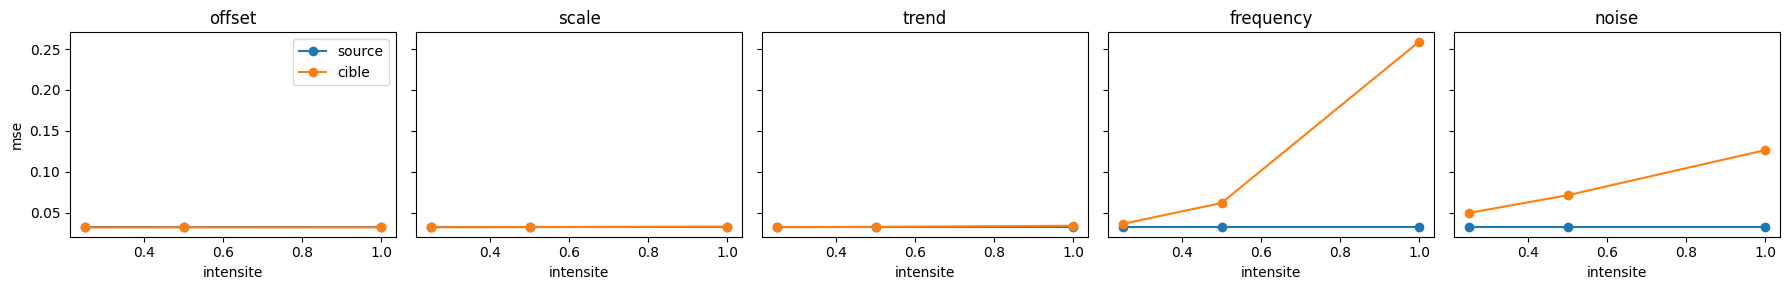

In [5]:
shift_types = ["offset", "scale", "trend", "frequency", "noise"]

fig, axes = plt.subplots(1, len(shift_types), figsize=(18, 3), sharey=True)
for ax, shift_type in zip(axes, shift_types):
    subset = results_df[results_df["shift_type"] == shift_type]
    ax.plot(subset["intensity"], subset["mse_source"], marker="o", label="source")
    ax.plot(subset["intensity"], subset["mse_target"], marker="o", label="cible")
    ax.set_title(shift_type)
    ax.set_xlabel("intensite")

axes[0].set_ylabel("mse")
axes[0].legend()
plt.tight_layout()
plt.show()

## Modele de reference : chaine de Markov d'ordre 1

contrairement a l'AR(p) qui utilise p=20 valeurs continues, on discretise la serie en n_states etats et on modelise uniquement la transition d'un etat au suivant (ordre 1)

In [6]:
def fit_discretizer(series, n_states=10):
    quantile_edges = np.quantile(series, np.linspace(0, 1, n_states + 1))
    bin_edges = quantile_edges.copy()
    bin_edges[0] = -np.inf
    bin_edges[-1] = np.inf

    states = np.digitize(series, bin_edges[1:-1])
    bin_centers = np.array([series[states == s].mean() for s in range(n_states)])

    return bin_edges, bin_centers


def discretize(series, bin_edges):
    return np.digitize(series, bin_edges[1:-1])

In [7]:
def fit_markov_chain(states_prev, states_next, n_states):
    transition_counts = np.zeros((n_states, n_states))
    for i, j in zip(states_prev, states_next):
        transition_counts[i, j] += 1

    row_sums = transition_counts.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    return transition_counts / row_sums

In [8]:
def evaluate_markov(Xs, ys, Xt, yt, n_states=10, test_ratio=0.2):
    split_idx = int(len(Xs) * (1 - test_ratio))

    prev_train, next_train = Xs[:split_idx, -1], ys[:split_idx]
    prev_test, next_test = Xs[split_idx:, -1], ys[split_idx:]

    bin_edges, bin_centers = fit_discretizer(prev_train, n_states)

    states_prev_train = discretize(prev_train, bin_edges)
    states_next_train = discretize(next_train, bin_edges)
    transition_matrix = fit_markov_chain(states_prev_train, states_next_train, n_states)

    states_prev_test = discretize(prev_test, bin_edges)
    pred_test = transition_matrix[states_prev_test] @ bin_centers
    mse_source = mean_squared_error(next_test, pred_test)

    states_prev_target = discretize(Xt[:, -1], bin_edges)
    pred_target = transition_matrix[states_prev_target] @ bin_centers
    mse_target = mean_squared_error(yt, pred_target)

    return mse_source, mse_target

## Evaluation systematique (Markov)

In [9]:
results_markov = []
for filepath in sorted(glob.glob("../data/synthetic/*.npz")):
    shift_type, intensity, window_size, series_source, Xt, yt = load_pair(filepath)
    Xs, ys = sliding_window(series_source, window_size)
    mse_source, mse_target = evaluate_markov(Xs, ys, Xt, yt)
    results_markov.append(dict(shift_type=shift_type, intensity=intensity, mse_source=mse_source, mse_target=mse_target))

results_markov_df = pd.DataFrame(results_markov).sort_values(["shift_type", "intensity"]).reset_index(drop=True)
results_markov_df

,shift_type,intensity,mse_source,mse_target
0,combined,0.25,1.354934,2.356420
1,combined,0.50,1.354934,7.203493
2,combined,1.00,1.354934,27.099208
3,frequency,0.25,1.354934,0.360273
4,frequency,0.50,1.354934,0.371128
5,frequency,1.00,1.354934,0.381902
6,noise,0.25,1.354934,0.372321
7,noise,0.50,1.354934,0.395394
8,noise,1.00,1.354934,0.449153
9,offset,0.25,1.354934,0.450933


## Comparaison AR(p) vs Markov

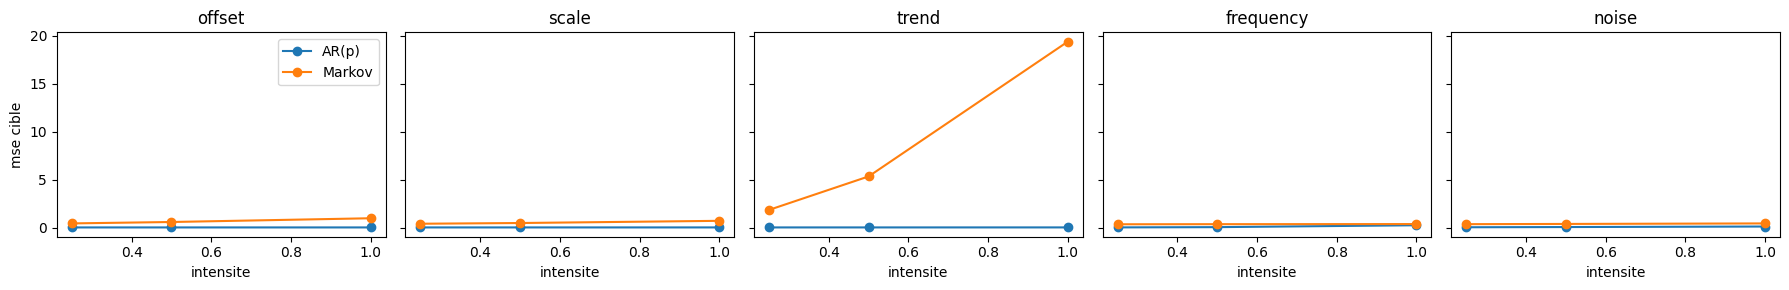

In [10]:
fig, axes = plt.subplots(1, len(shift_types), figsize=(18, 3), sharey=True)
for ax, shift_type in zip(axes, shift_types):
    subset_ar = results_df[results_df["shift_type"] == shift_type]
    subset_markov = results_markov_df[results_markov_df["shift_type"] == shift_type]
    ax.plot(subset_ar["intensity"], subset_ar["mse_target"], marker="o", label="AR(p)")
    ax.plot(subset_markov["intensity"], subset_markov["mse_target"], marker="o", label="Markov")
    ax.set_title(shift_type)
    ax.set_xlabel("intensite")

axes[0].set_ylabel("mse cible")
axes[0].legend()
plt.tight_layout()
plt.show()

## ADAPT sur le shift frequency

In [11]:
from adapt.feature_based import CORAL

In [12]:
results_coral = []
for filepath in sorted(glob.glob("../data/synthetic/frequency_intensity_*.npz")):
    shift_type, intensity, window_size, series_source, Xt, yt = load_pair(filepath)
    mse_target_baseline = evaluate_baseline(series_source, window_size, Xt, yt, LinearRegression())["mse_target"]
    mse_target_coral = evaluate_adapt(CORAL, series_source, window_size, Xt, yt, LinearRegression())["mse_target"]
    results_coral.append(dict(intensity=intensity, mse_target_baseline=mse_target_baseline, mse_target_coral=mse_target_coral))

results_coral_df = pd.DataFrame(results_coral).sort_values("intensity").reset_index(drop=True)
results_coral_df

,intensity,mse_target_baseline,mse_target_coral
0,0.25,0.036298,1.991722
1,0.50,0.061869,1.995008
2,1.00,0.259065,2.119610


## Visualisation

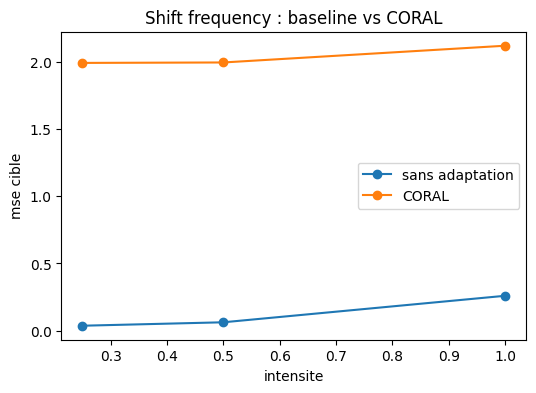

In [13]:
plt.figure(figsize=(6, 4))
plt.plot(results_coral_df["intensity"], results_coral_df["mse_target_baseline"], marker="o", label="sans adaptation")
plt.plot(results_coral_df["intensity"], results_coral_df["mse_target_coral"], marker="o", label="CORAL")
plt.xlabel("intensite")
plt.ylabel("mse cible")
plt.title("Shift frequency : baseline vs CORAL")
plt.legend()
plt.show()